# CLAM-TR v3 Improved: Enhanced Model for ISUP Grading
## Target: QWK 0.83 -> 0.90, Accuracy 63% -> 70%

**Improvements over original CLAM-TR:**
- K=256 (was 128) - ablation showed this is best
- CombinedOrdinalLoss with focal weighting and ordinal penalty
- Fixed distance normalization (not slide-dependent)
- Learnable fusion gate between CLAM and Retention paths
- LayerNorm throughout for training stability
- Gradient clipping (max_norm=1.0)
- 75 epochs (was 50)
- Higher learning rate (2e-4 vs 1e-4)

**CRITICAL:** This notebook reuses existing UNI features - NO re-extraction needed!

**Dataset:** PANDA 600-slide subset (80/20 stratified split)

---
## Section 1: Setup & Configuration

In [1]:
!pip install -q openslide-python timm scikit-learn pandas matplotlib seaborn tqdm

In [2]:
import os, json, time, random
from pathlib import Path
from datetime import datetime, timedelta
from typing import Dict, List, Tuple, Optional, Any
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam
from torch.optim.lr_scheduler import CosineAnnealingLR
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import cohen_kappa_score, accuracy_score, f1_score, roc_auc_score, confusion_matrix, precision_recall_fscore_support
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
drive.mount('/content/drive')
print('All imports successful!')

Mounted at /content/drive
All imports successful!


In [3]:
# ============================================================================
# IMPROVED CONFIGURATION - v3
# ============================================================================

CONFIG = {
    # READ-ONLY paths (shared - don't modify)
    'original_slides': '/content/drive/MyDrive/panda-data/prostate-cancer-grade-assessment/train_images/',
    'ground_truth_masks': '/content/drive/MyDrive/panda-data/prostate-cancer-grade-assessment/train_label_masks/',
    'subset_folder': '/content/drive/MyDrive/PANDA_Subset_600/images/',
    'csv_path': '/content/drive/MyDrive/panda-data/prostate-cancer-grade-assessment/train.csv',
    'preprocessing_dir': '/content/drive/MyDrive/CLAM_TR_Preprocessing/',
    'features_dir': '/content/drive/MyDrive/CLAM_TR_Features/',

    # WRITE paths (v3_improved - separate from other notebooks)
    'checkpoints_dir': '/content/drive/MyDrive/CLAM_TR_Checkpoints/v3_improved/',
    'results_dir': '/content/drive/MyDrive/CLAM_TR_Results/v3_improved/',

    # Improved model parameters
    'patch_size': 256,
    'magnification': '20x',
    'feature_dim': 1024,
    'hidden_dim': 512,
    'n_classes': 6,
    'dropout': 0.3,           # Changed from 0.25
    'K': 256,                 # Changed from 128 (ablation showed this is best)
    'num_heads': 8,
    'gamma_values': [0.80, 0.85, 0.90, 0.93, 0.95, 0.97, 0.98, 0.99],

    # Improved training parameters
    'epochs': 75,             # Changed from 50
    'lr': 2e-4,               # Changed from 1e-4
    'weight_decay': 1e-4,     # Changed from 1e-5
    'label_smoothing': 0.15,  # Changed from 0.1
    'ordinal_weight': 0.3,    # NEW - for ordinal loss
    'max_grad_norm': 1.0,     # NEW - gradient clipping
    'seed': 42,
    'train_ratio': 0.8,
    'val_ratio': 0.2,
    'checkpoint_freq_epochs': 5,
    'checkpoint_freq_minutes': 30,
}

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(CONFIG['seed'])
print(f'Seeds set to {CONFIG["seed"]}')

# Print key improvements
print('\n' + '='*60)
print('CLAM-TR v3 IMPROVEMENTS')
print('='*60)
print(f'  K: 128 -> {CONFIG["K"]}')
print(f'  Dropout: 0.25 -> {CONFIG["dropout"]}')
print(f'  Epochs: 50 -> {CONFIG["epochs"]}')
print(f'  Learning Rate: 1e-4 -> {CONFIG["lr"]}')
print(f'  Weight Decay: 1e-5 -> {CONFIG["weight_decay"]}')
print(f'  Label Smoothing: 0.1 -> {CONFIG["label_smoothing"]}')
print(f'  Ordinal Weight: NEW -> {CONFIG["ordinal_weight"]}')
print(f'  Gradient Clipping: NEW -> {CONFIG["max_grad_norm"]}')
print('='*60)

Seeds set to 42

CLAM-TR v3 IMPROVEMENTS
  K: 128 -> 256
  Dropout: 0.25 -> 0.3
  Epochs: 50 -> 75
  Learning Rate: 1e-4 -> 0.0002
  Weight Decay: 1e-5 -> 0.0001
  Label Smoothing: 0.1 -> 0.15
  Ordinal Weight: NEW -> 0.3
  Gradient Clipping: NEW -> 1.0


In [4]:
def detect_gpu_and_set_batch_size():
    if not torch.cuda.is_available():
        print('WARNING: No GPU detected!')
        return {'feature_extraction': 32, 'training': 1}
    gpu_name = torch.cuda.get_device_name(0).lower()
    gpu_memory = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f'GPU: {torch.cuda.get_device_name(0)}, Memory: {gpu_memory:.1f} GB')
    if 'h100' in gpu_name or 'a100' in gpu_name:
        batch_sizes = {'feature_extraction': 512, 'training': 1}
    elif 'l4' in gpu_name:
        batch_sizes = {'feature_extraction': 256, 'training': 1}
    else:
        batch_sizes = {'feature_extraction': 128, 'training': 1}
    return batch_sizes

BATCH_SIZES = detect_gpu_and_set_batch_size()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {DEVICE}')

GPU: Tesla T4, Memory: 15.8 GB
Using device: cuda


In [5]:
def create_directories():
    """Create v3_improved specific directories."""
    dirs = [
        CONFIG['checkpoints_dir'],
        CONFIG['results_dir'],
        os.path.join(CONFIG['results_dir'], 'visualizations'),
        os.path.join(CONFIG['results_dir'], 'models')
    ]
    for d in dirs:
        os.makedirs(d, exist_ok=True)
    print('v3_improved directories created!')
    print(f'  Checkpoints: {CONFIG["checkpoints_dir"]}')
    print(f'  Results: {CONFIG["results_dir"]}')

create_directories()

v3_improved directories created!
  Checkpoints: /content/drive/MyDrive/CLAM_TR_Checkpoints/v3_improved/
  Results: /content/drive/MyDrive/CLAM_TR_Results/v3_improved/


---
## Section 2: CheckpointManager Class

In [6]:
class CheckpointManager:
    """Manages checkpoints for v3_improved experiments."""
    def __init__(self, checkpoint_dir):
        self.checkpoint_dir = checkpoint_dir
        os.makedirs(checkpoint_dir, exist_ok=True)
        self.progress_files = {
            'experiments': os.path.join(checkpoint_dir, 'experiment_progress.json')
        }

    def _save_json(self, filepath, data):
        for attempt in range(3):
            try:
                with open(filepath, 'w') as f:
                    json.dump(data, f, indent=2)
                return
            except:
                time.sleep(1)

    def _load_json(self, filepath):
        if os.path.exists(filepath):
            try:
                with open(filepath, 'r') as f:
                    return json.load(f)
            except:
                return {}
        return {}

    def save_training_checkpoint(self, experiment_name, epoch, model_state, optimizer_state, scheduler_state, best_qwk, metrics_history):
        checkpoint_path = os.path.join(self.checkpoint_dir, f'{experiment_name}_checkpoint.pt')
        torch.save({
            'epoch': epoch,
            'model_state_dict': model_state,
            'optimizer_state_dict': optimizer_state,
            'scheduler_state_dict': scheduler_state,
            'best_qwk': best_qwk,
            'metrics_history': metrics_history,
            'timestamp': datetime.now().isoformat()
        }, checkpoint_path)
        return checkpoint_path

    def load_training_checkpoint(self, experiment_name):
        checkpoint_path = os.path.join(self.checkpoint_dir, f'{experiment_name}_checkpoint.pt')
        if os.path.exists(checkpoint_path):
            try:
                return torch.load(checkpoint_path, map_location=DEVICE)
            except:
                return None
        return None

    def get_completed_experiments(self):
        return self._load_json(self.progress_files['experiments'])

    def save_experiment_result(self, experiment_name, metrics, model_path):
        data = self._load_json(self.progress_files['experiments'])
        data[experiment_name] = {
            'metrics': metrics,
            'model_path': model_path,
            'completed_at': datetime.now().isoformat()
        }
        self._save_json(self.progress_files['experiments'], data)

    def is_experiment_completed(self, experiment_name):
        return experiment_name in self._load_json(self.progress_files['experiments'])

checkpoint_manager = CheckpointManager(CONFIG['checkpoints_dir'])
print('CheckpointManager initialized for v3_improved!')

CheckpointManager initialized for v3_improved!


---
## Section 6: Model Definitions (IMPROVED)

In [7]:
# Gated Attention (same as original)
class GatedAttention(nn.Module):
    def __init__(self, input_dim=1024, hidden_dim=512, dropout=0.25):
        super().__init__()
        self.attention_a = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Dropout(dropout)
        )
        self.attention_b = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Sigmoid(),
            nn.Dropout(dropout)
        )
        self.attention_c = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        return self.attention_c(self.attention_a(x) * self.attention_b(x)).squeeze(-1)

In [8]:
# ============================================================================
# IMPROVED SPATIAL RETENTION - v3
# Key changes:
#   1. FIXED distance normalization (not slide-dependent)
#   2. LayerNorm in output projection
#   3. Dropout in output projection
# ============================================================================

class ImprovedSpatialRetentionHead(nn.Module):
    """Spatial retention with FIXED distance normalization (not slide-dependent)."""
    def __init__(self, hidden_dim, gamma=0.9, patch_size=256):
        super().__init__()
        self.gamma = gamma
        self.patch_size = patch_size
        self.head_dim = hidden_dim // 8

        self.W_Q = nn.Linear(hidden_dim, self.head_dim, bias=False)
        self.W_K = nn.Linear(hidden_dim, self.head_dim, bias=False)
        self.W_V = nn.Linear(hidden_dim, self.head_dim, bias=False)

    def forward(self, x, coords):
        Q, K, V = self.W_Q(x), self.W_K(x), self.W_V(x)

        # Compute distances
        diff = coords.unsqueeze(0) - coords.unsqueeze(1)
        distances = torch.norm(diff.float(), dim=-1)

        # FIXED normalization (not max-based like before)
        # This ensures consistent behavior across different slides
        normalized_distances = distances / (self.patch_size * 10)

        # Distance decay
        D = self.gamma ** normalized_distances

        # Attention scores
        scores = torch.matmul(Q, K.transpose(-2, -1)) / (self.head_dim ** 0.5)
        scores = scores * D
        attn = F.softmax(scores, dim=-1)

        return torch.matmul(attn, V)


class ImprovedSpatialRetention(nn.Module):
    """Multi-head spatial retention with LayerNorm."""
    def __init__(self, hidden_dim=512, num_heads=8, gamma_values=None, patch_size=256):
        super().__init__()
        if gamma_values is None:
            gamma_values = [0.80, 0.85, 0.90, 0.93, 0.95, 0.97, 0.98, 0.99]

        self.heads = nn.ModuleList([
            ImprovedSpatialRetentionHead(hidden_dim, gamma_values[i], patch_size)
            for i in range(num_heads)
        ])
        self.output_proj = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.Dropout(0.1)
        )

    def forward(self, x, coords):
        head_outputs = [h(x, coords) for h in self.heads]
        concatenated = torch.cat(head_outputs, dim=-1)
        return self.output_proj(concatenated)

print('ImprovedSpatialRetention defined!')

ImprovedSpatialRetention defined!


In [9]:
# ============================================================================
# CLAM-TR IMPROVED - v3
# Key changes:
#   1. LayerNorm throughout for stability
#   2. Learnable fusion of CLAM and Retention paths
#   3. Fixed distance normalization in spatial retention
#   4. Pre-classifier LayerNorm and Dropout
# ============================================================================

class CLAM_TR_Improved(nn.Module):
    """
    CLAM-TR with improvements:
    1. LayerNorm throughout for stability
    2. Learnable fusion of CLAM and Retention paths
    3. Fixed distance normalization in spatial retention
    """
    def __init__(self, input_dim=1024, hidden_dim=512, n_classes=6,
                 dropout=0.3, K=256, num_heads=8, gamma_values=None, patch_size=256):
        super().__init__()
        self.K = K

        # Feature transform with LayerNorm
        self.feature_transform = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # Improved gated attention with LayerNorm
        self.attention_a = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.LayerNorm(hidden_dim // 2),
            nn.Tanh(),
            nn.Dropout(dropout)
        )
        self.attention_b = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.LayerNorm(hidden_dim // 2),
            nn.Sigmoid(),
            nn.Dropout(dropout)
        )
        self.attention_c = nn.Linear(hidden_dim // 2, 1)

        # Improved spatial retention
        self.spatial_retention = ImprovedSpatialRetention(
            hidden_dim, num_heads, gamma_values, patch_size
        )

        # Learnable fusion gate (NEW)
        self.fusion_gate = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout / 2),
            nn.Linear(hidden_dim, 2),
            nn.Softmax(dim=-1)
        )

        # Pre-classifier norm (NEW)
        self.pre_classifier = nn.Sequential(
            nn.LayerNorm(hidden_dim),
            nn.Dropout(dropout)
        )

        # Classifier
        self.classifier = nn.Linear(hidden_dim, n_classes)

    def forward(self, x, coords, return_attention=False):
        # Feature transformation
        h = self.feature_transform(x)

        # Gated attention
        a = self.attention_a(h)
        b = self.attention_b(h)
        A = self.attention_c(a * b).squeeze(-1)
        A_softmax = F.softmax(A, dim=0)

        # Top-K selection
        K_actual = min(self.K, h.size(0))
        topk_indices = torch.topk(A, K_actual).indices

        h_topk = h[topk_indices]
        coords_topk = coords[topk_indices]
        A_topk = A_softmax[topk_indices]

        # Path 1: CLAM aggregation
        M_clam = torch.sum(A_topk.unsqueeze(-1) * h_topk, dim=0)

        # Path 2: Spatial retention
        retention_out = self.spatial_retention(h_topk, coords_topk)
        M_retention = torch.mean(retention_out, dim=0)

        # Learnable fusion (NEW)
        fusion_input = torch.cat([M_clam, M_retention], dim=-1)
        weights = self.fusion_gate(fusion_input.unsqueeze(0)).squeeze(0)
        M = weights[0] * M_clam + weights[1] * M_retention

        # Pre-classifier (NEW)
        M = self.pre_classifier(M)

        # Classification
        logits = self.classifier(M)

        if return_attention:
            full_attn = torch.zeros_like(A_softmax)
            full_attn[topk_indices] = A_topk
            return logits, full_attn, topk_indices
        return logits

print('CLAM_TR_Improved defined!')

CLAM_TR_Improved defined!


---
## Section 7: Dataset & DataLoader

In [10]:
class PANDAFeatureDataset(Dataset):
    """Dataset that loads pre-extracted features."""
    def __init__(self, slide_ids, labels, features_dir):
        self.slide_ids = slide_ids
        self.labels = labels
        self.features_dir = features_dir

    def __len__(self):
        return len(self.slide_ids)

    def __getitem__(self, idx):
        data = torch.load(
            os.path.join(self.features_dir, f'{self.slide_ids[idx]}.pt'),
            map_location='cpu'
        )
        return data['features'], data['coordinates'], self.labels[idx], self.slide_ids[idx]

def collate_fn(batch):
    return batch[0][0], batch[0][1], batch[0][2], batch[0][3]

def create_dataloaders(encoder_name):
    """Create train/val dataloaders using existing features."""
    # Use the ORIGINAL checkpoints dir to get the subset CSV
    original_ckpt_dir = '/content/drive/MyDrive/CLAM_TR_Checkpoints/'
    subset_csv = os.path.join(original_ckpt_dir, 'subset_600.csv')

    if not os.path.exists(subset_csv):
        print(f'ERROR: Subset CSV not found: {subset_csv}')
        print('Please run the original notebook first to create the subset.')
        return None, None, None, None

    df = pd.read_csv(subset_csv)
    features_dir = os.path.join(CONFIG['features_dir'], encoder_name)

    if not os.path.exists(features_dir):
        print(f'ERROR: Features directory not found: {features_dir}')
        return None, None, None, None

    available = set(f.replace('.pt', '') for f in os.listdir(features_dir) if f.endswith('.pt'))

    if len(available) == 0:
        print(f'ERROR: No feature files found in {features_dir}')
        return None, None, None, None

    df = df[df['image_id'].isin(available)].reset_index(drop=True)

    if len(df) < 10:
        print(f'ERROR: Not enough samples ({len(df)}) for training with {encoder_name}')
        return None, None, None, None

    train_df, val_df = train_test_split(
        df,
        test_size=CONFIG['val_ratio'],
        stratify=df['isup_grade'],
        random_state=CONFIG['seed']
    )

    print(f'{encoder_name}: Train={len(train_df)}, Val={len(val_df)}')

    train_ds = PANDAFeatureDataset(
        train_df['image_id'].tolist(),
        train_df['isup_grade'].tolist(),
        features_dir
    )
    val_ds = PANDAFeatureDataset(
        val_df['image_id'].tolist(),
        val_df['isup_grade'].tolist(),
        features_dir
    )

    return (
        DataLoader(train_ds, batch_size=1, shuffle=True, collate_fn=collate_fn),
        DataLoader(val_ds, batch_size=1, shuffle=False, collate_fn=collate_fn),
        train_df,
        val_df
    )

print('Dataset and DataLoader defined!')

Dataset and DataLoader defined!


---
## Section 8: Loss Function & Training Functions (IMPROVED)

In [11]:
# ============================================================================
# COMBINED ORDINAL LOSS - v3 (NEW)
# Key improvements:
#   1. Label smoothing cross-entropy
#   2. Ordinal penalty (grades are ordered: 0 < 1 < 2 < 3 < 4 < 5)
#   3. Focal weighting (focus on hard examples)
# ============================================================================

class CombinedOrdinalLoss(nn.Module):
    """
    Combined loss for ISUP grading:
    1. Label smoothing cross-entropy
    2. Ordinal penalty (grades are ordered: 0 < 1 < 2 < 3 < 4 < 5)
    3. Focal weighting (focus on hard examples)

    This improves both QWK and Accuracy for ordinal classification.
    """
    def __init__(self, n_classes=6, smoothing=0.15, ordinal_weight=0.3, focal_gamma=2.0):
        super().__init__()
        self.n_classes = n_classes
        self.smoothing = smoothing
        self.ordinal_weight = ordinal_weight
        self.focal_gamma = focal_gamma

    def forward(self, pred, target):
        # Handle dimensions
        if pred.dim() == 1:
            pred = pred.unsqueeze(0)
        if target.dim() == 0:
            target = target.unsqueeze(0)

        # 1. Label Smoothing Cross-Entropy
        confidence = 1.0 - self.smoothing
        smooth_label = self.smoothing / (self.n_classes - 1)
        one_hot = torch.zeros_like(pred).scatter_(1, target.unsqueeze(1), 1)
        smooth_target = one_hot * confidence + (1 - one_hot) * smooth_label

        log_probs = F.log_softmax(pred, dim=1)
        ce_loss = -(smooth_target * log_probs).sum(dim=1)

        # 2. Focal weighting
        probs = torch.exp(log_probs)
        pt = probs.gather(1, target.unsqueeze(1)).squeeze(1)
        focal_weight = (1 - pt) ** self.focal_gamma

        # 3. Ordinal penalty
        class_indices = torch.arange(self.n_classes, device=pred.device, dtype=torch.float)
        expected_class = torch.sum(probs * class_indices.unsqueeze(0), dim=1)
        ordinal_loss = (expected_class - target.float()) ** 2

        total_loss = focal_weight * ce_loss + self.ordinal_weight * ordinal_loss
        return total_loss.mean()

print('CombinedOrdinalLoss defined!')

CombinedOrdinalLoss defined!


In [12]:
# ============================================================================
# TRAINING FUNCTIONS - v3 (with gradient clipping)
# ============================================================================

def train_one_epoch(model, loader, optimizer, criterion, device, model_type='clam_tr'):
    """Train for one epoch with gradient clipping."""
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for features, coords, label, _ in tqdm(loader, desc='Train', leave=False):
        features, coords = features.to(device), coords.to(device)
        label = torch.tensor(label).to(device)

        optimizer.zero_grad()

        if model_type == 'clam':
            logits = model(features)
        else:
            logits = model(features, coords)

        loss = criterion(logits.unsqueeze(0), label.unsqueeze(0))
        loss.backward()

        # NEW: Gradient clipping for stability
        torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG['max_grad_norm'])

        optimizer.step()

        total_loss += loss.item()
        correct += (logits.argmax() == label).item()
        total += 1

    return total_loss / total, correct / total


def validate(model, loader, criterion, device, model_type='clam_tr'):
    """Validate the model."""
    model.eval()
    total_loss, preds, labels, probs = 0.0, [], [], []

    with torch.no_grad():
        for features, coords, label, _ in tqdm(loader, desc='Val', leave=False):
            features, coords = features.to(device), coords.to(device)
            label_t = torch.tensor(label).to(device)

            if model_type == 'clam':
                logits = model(features)
            else:
                logits = model(features, coords)

            total_loss += criterion(logits.unsqueeze(0), label_t.unsqueeze(0)).item()
            preds.append(logits.argmax().cpu().item())
            labels.append(label)
            probs.append(F.softmax(logits, dim=0).cpu().numpy())

    return total_loss / len(loader), preds, labels, np.array(probs)

print('Training functions defined!')

Training functions defined!


---
## Section 9: Metrics Calculation

In [13]:
def calculate_metrics(y_true, y_pred, y_probs):
    """Calculate all evaluation metrics."""
    metrics = {
        'qwk': cohen_kappa_score(y_true, y_pred, weights='quadratic'),
        'accuracy': accuracy_score(y_true, y_pred),
        'macro_f1': f1_score(y_true, y_pred, average='macro'),
        'auc': roc_auc_score(y_true, y_probs, multi_class='ovr', average='macro') if len(np.unique(y_true)) > 1 else 0.0
    }
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average=None, labels=list(range(CONFIG['n_classes']))
    )
    metrics['per_class_f1'] = f1.tolist()
    metrics['confusion_matrix'] = confusion_matrix(y_true, y_pred).tolist()
    return metrics

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print('Metrics functions defined!')

Metrics functions defined!


In [14]:
def run_training(model, train_loader, val_loader, experiment_name, model_type='clam_tr'):
    """Run training loop with improved loss and gradient clipping."""
    print(f'\n{"="*60}')
    print(f'Training: {experiment_name}')
    print(f'{"="*60}')

    if checkpoint_manager.is_experiment_completed(experiment_name):
        print('Already completed!')
        return checkpoint_manager.get_completed_experiments()[experiment_name]['metrics']

    model = model.to(DEVICE)

    # NEW: Use CombinedOrdinalLoss instead of LabelSmoothingLoss
    criterion = CombinedOrdinalLoss(
        n_classes=CONFIG['n_classes'],
        smoothing=CONFIG['label_smoothing'],
        ordinal_weight=CONFIG['ordinal_weight']
    )

    optimizer = Adam(model.parameters(), lr=CONFIG['lr'], weight_decay=CONFIG['weight_decay'])
    scheduler = CosineAnnealingLR(optimizer, T_max=CONFIG['epochs'])

    checkpoint = checkpoint_manager.load_training_checkpoint(experiment_name)
    start_epoch, best_qwk = 0, -1
    metrics_history = {'train_loss': [], 'val_loss': [], 'val_qwk': [], 'val_acc': []}

    if checkpoint:
        print(f'Resuming from epoch {checkpoint["epoch"]}')
        model.load_state_dict(checkpoint['model_state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
        start_epoch = checkpoint['epoch'] + 1
        best_qwk = checkpoint['best_qwk']
        metrics_history = checkpoint['metrics_history']

    last_ckpt_time = time.time()

    for epoch in range(start_epoch, CONFIG['epochs']):
        train_loss, train_acc = train_one_epoch(
            model, train_loader, optimizer, criterion, DEVICE, model_type
        )
        val_loss, preds, labels, probs = validate(
            model, val_loader, criterion, DEVICE, model_type
        )

        qwk = cohen_kappa_score(labels, preds, weights='quadratic')
        acc = accuracy_score(labels, preds)

        metrics_history['train_loss'].append(train_loss)
        metrics_history['val_loss'].append(val_loss)
        metrics_history['val_qwk'].append(qwk)
        metrics_history['val_acc'].append(acc)

        scheduler.step()

        if qwk > best_qwk:
            best_qwk = qwk
            model_path = os.path.join(CONFIG['results_dir'], 'models', f'{experiment_name}_best.pt')
            torch.save(model.state_dict(), model_path)
            print(f'Epoch {epoch+1}/{CONFIG["epochs"]} - Train Loss: {train_loss:.4f}, Val QWK: {qwk:.4f}*, Acc: {acc:.4f}')
        else:
            print(f'Epoch {epoch+1}/{CONFIG["epochs"]} - Train Loss: {train_loss:.4f}, Val QWK: {qwk:.4f}, Acc: {acc:.4f}')

        # Checkpoint saving
        should_save = (
            (epoch + 1) % CONFIG['checkpoint_freq_epochs'] == 0 or
            (time.time() - last_ckpt_time) > CONFIG['checkpoint_freq_minutes'] * 60
        )
        if should_save:
            checkpoint_manager.save_training_checkpoint(
                experiment_name, epoch, model.state_dict(),
                optimizer.state_dict(), scheduler.state_dict(),
                best_qwk, metrics_history
            )
            last_ckpt_time = time.time()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # Load best model and compute final metrics
    model.load_state_dict(torch.load(
        os.path.join(CONFIG['results_dir'], 'models', f'{experiment_name}_best.pt'),
        map_location=DEVICE
    ))
    _, preds, labels, probs = validate(model, val_loader, criterion, DEVICE, model_type)
    final_metrics = calculate_metrics(labels, preds, probs)
    final_metrics['metrics_history'] = metrics_history

    checkpoint_manager.save_experiment_result(
        experiment_name, final_metrics, f'{experiment_name}_best.pt'
    )

    print(f'\nFinal QWK: {final_metrics["qwk"]:.4f}, Acc: {final_metrics["accuracy"]:.4f}')
    return final_metrics

print('run_training function defined!')

run_training function defined!


---
## Section 10: Run Improved Experiment

In [15]:
def run_improved_experiment():
    """Run only the improved UNI + CLAM-TR experiment."""

    experiment_name = 'exp4_uni_clam_tr_improved'

    print(f'\n{"="*60}')
    print(f'IMPROVED EXPERIMENT: {experiment_name}')
    print(f'{"="*60}')
    print(f'Improvements:')
    print(f'  - K=256 (was 128)')
    print(f'  - Ordinal loss (new)')
    print(f'  - Fixed distance normalization (new)')
    print(f'  - Learnable fusion (new)')
    print(f'  - LayerNorm throughout (new)')
    print(f'  - Gradient clipping (new)')
    print(f'  - 75 epochs (was 50)')
    print(f'  - LR 2e-4 (was 1e-4)')
    print(f'{"="*60}')

    # Check if already completed
    if checkpoint_manager.is_experiment_completed(experiment_name):
        print('Already completed! Loading saved results...')
        return checkpoint_manager.get_completed_experiments()[experiment_name]['metrics']

    # Create dataloaders (reuse existing UNI features)
    train_loader, val_loader, train_df, val_df = create_dataloaders('uni')

    if train_loader is None:
        print('ERROR: UNI features not found!')
        print('Please run the original notebook first to extract features.')
        return None

    # Create improved model
    model = CLAM_TR_Improved(
        input_dim=CONFIG['feature_dim'],
        hidden_dim=CONFIG['hidden_dim'],
        n_classes=CONFIG['n_classes'],
        dropout=CONFIG['dropout'],
        K=CONFIG['K'],
        num_heads=CONFIG['num_heads'],
        gamma_values=CONFIG['gamma_values'],
        patch_size=CONFIG['patch_size']
    )

    print(f'Model parameters: {count_parameters(model):,}')

    # Train with improved loss
    metrics = run_training(model, train_loader, val_loader, experiment_name, 'clam_tr')

    # Print results
    print(f'\n{"="*60}')
    print(f'RESULTS: {experiment_name}')
    print(f'{"="*60}')
    print(f'QWK:      {metrics["qwk"]:.4f}')
    print(f'Accuracy: {metrics["accuracy"]:.4f}')
    print(f'Macro F1: {metrics["macro_f1"]:.4f}')
    print(f'{"="*60}')

    return metrics

print('run_improved_experiment function defined!')

run_improved_experiment function defined!


---
## Section 11: Visualization Functions

In [16]:
def plot_confusion_matrix(results, experiment_name):
    """Plot confusion matrix for the experiment."""
    if experiment_name not in results:
        print(f'No results found for {experiment_name}')
        return

    cm = np.array(results[experiment_name]['confusion_matrix'])

    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', ax=ax,
        xticklabels=[f'G{i}' for i in range(6)],
        yticklabels=[f'G{i}' for i in range(6)]
    )
    ax.set_title(f'{experiment_name}\nQWK: {results[experiment_name]["qwk"]:.4f}, Acc: {results[experiment_name]["accuracy"]:.4f}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

    plt.tight_layout()
    plt.savefig(
        os.path.join(CONFIG['results_dir'], 'visualizations', f'{experiment_name}_confusion_matrix.png'),
        dpi=300
    )
    plt.show()

def plot_training_curves(results, experiment_name):
    """Plot training curves for the experiment."""
    if experiment_name not in results:
        print(f'No results found for {experiment_name}')
        return

    if 'metrics_history' not in results[experiment_name]:
        print('No metrics history found')
        return

    history = results[experiment_name]['metrics_history']

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Loss curve
    axes[0].plot(history['train_loss'], label='Train Loss')
    axes[0].plot(history['val_loss'], label='Val Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Loss Curves')
    axes[0].legend()

    # QWK and Accuracy curves
    axes[1].plot(history['val_qwk'], label='Val QWK')
    axes[1].plot(history['val_acc'], label='Val Accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Score')
    axes[1].set_title('Performance Curves')
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(
        os.path.join(CONFIG['results_dir'], 'visualizations', f'{experiment_name}_training_curves.png'),
        dpi=300
    )
    plt.show()

print('Visualization functions defined!')

Visualization functions defined!


---
## Section 12: Execute Improved Experiment

In [17]:
# ============================================================================
# VERIFY FEATURES EXIST BEFORE TRAINING
# ============================================================================

print('='*60)
print('VERIFYING UNI FEATURES')
print('='*60)

uni_dir = os.path.join(CONFIG['features_dir'], 'uni')

if os.path.exists(uni_dir):
    n_features = len([f for f in os.listdir(uni_dir) if f.endswith('.pt')])
    print(f'UNI features found: {n_features}/600')

    if n_features >= 600:
        print('\n' + '='*60)
        print('READY TO TRAIN! No re-extraction needed.')
        print('='*60)

        # Check sample file
        sample_file = [f for f in os.listdir(uni_dir) if f.endswith('.pt')][0]
        data = torch.load(os.path.join(uni_dir, sample_file), map_location='cpu')
        print(f'\nSample feature file: {sample_file}')
        print(f'  Features shape: {data["features"].shape}')
        print(f'  Coordinates shape: {data["coordinates"].shape}')
    else:
        print(f'\nWARNING: Only {n_features}/600 features found.')
        print('Please run the original notebook to complete feature extraction.')
else:
    print(f'ERROR: UNI features directory not found: {uni_dir}')
    print('Please run the original notebook first to extract features.')

VERIFYING UNI FEATURES
UNI features found: 600/600

READY TO TRAIN! No re-extraction needed.

Sample feature file: 6b69560eba8205a182f996d752402036.pt
  Features shape: torch.Size([355, 1024])
  Coordinates shape: torch.Size([355, 2])


In [18]:
# ============================================================================
# RUN IMPROVED EXPERIMENT
# ============================================================================

print('\n' + '='*60)
print('STARTING CLAM-TR v3 IMPROVED TRAINING')
print('='*60)
print(f'\nTarget improvements:')
print(f'  QWK: 0.83 -> 0.90')
print(f'  Accuracy: 63% -> 70%')
print('='*60 + '\n')

# Run the improved experiment
results = run_improved_experiment()

if results is not None:
    print('\n' + '='*60)
    print('EXPERIMENT COMPLETE!')
    print('='*60)


STARTING CLAM-TR v3 IMPROVED TRAINING

Target improvements:
  QWK: 0.83 -> 0.90
  Accuracy: 63% -> 70%


IMPROVED EXPERIMENT: exp4_uni_clam_tr_improved
Improvements:
  - K=256 (was 128)
  - Ordinal loss (new)
  - Fixed distance normalization (new)
  - Learnable fusion (new)
  - LayerNorm throughout (new)
  - Gradient clipping (new)
  - 75 epochs (was 50)
  - LR 2e-4 (was 1e-4)
uni: Train=480, Val=120
Model parameters: 2,369,801

Training: exp4_uni_clam_tr_improved


Train:   0%|          | 0/480 [00:00<?, ?it/s]

Val:   0%|          | 0/120 [00:00<?, ?it/s]

Epoch 1/75 - Train Loss: 1.5369, Val QWK: 0.7920*, Acc: 0.5917


Train:   0%|          | 0/480 [00:00<?, ?it/s]

Val:   0%|          | 0/120 [00:00<?, ?it/s]

... (218 outputs left out)

Val:   0%|          | 0/120 [00:00<?, ?it/s]

Epoch 75/75 - Train Loss: 0.0001, Val QWK: 0.7323, Acc: 0.5250


Val:   0%|          | 0/120 [00:00<?, ?it/s]


Final QWK: 0.8106, Acc: 0.6083

RESULTS: exp4_uni_clam_tr_improved
QWK:      0.8106
Accuracy: 0.6083
Macro F1: 0.6103

EXPERIMENT COMPLETE!



Generating visualizations...


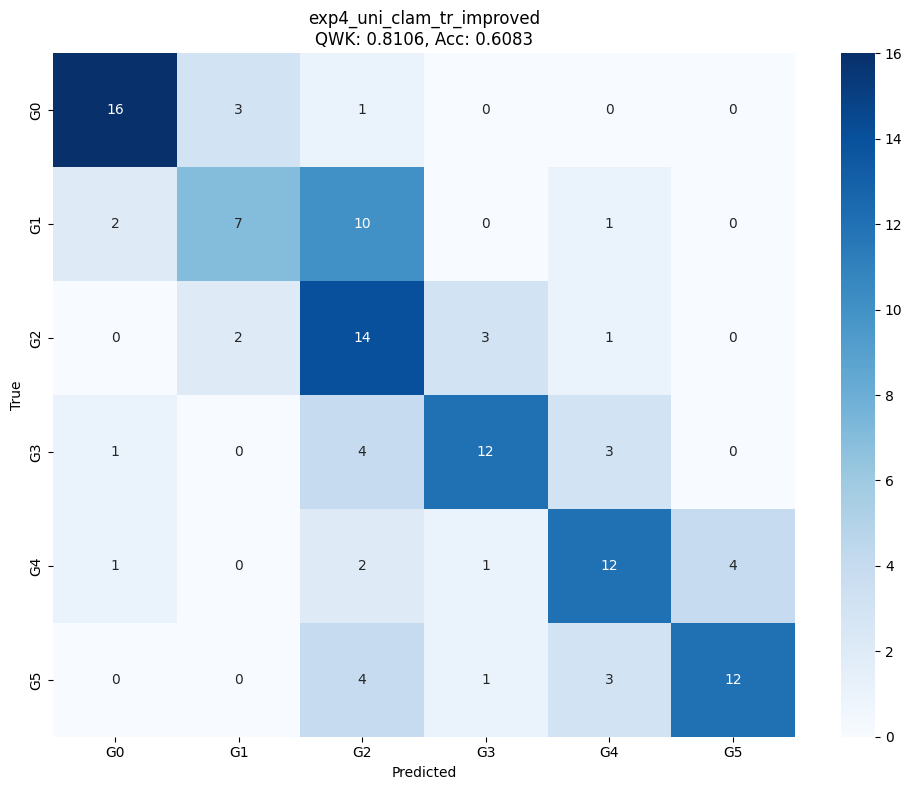

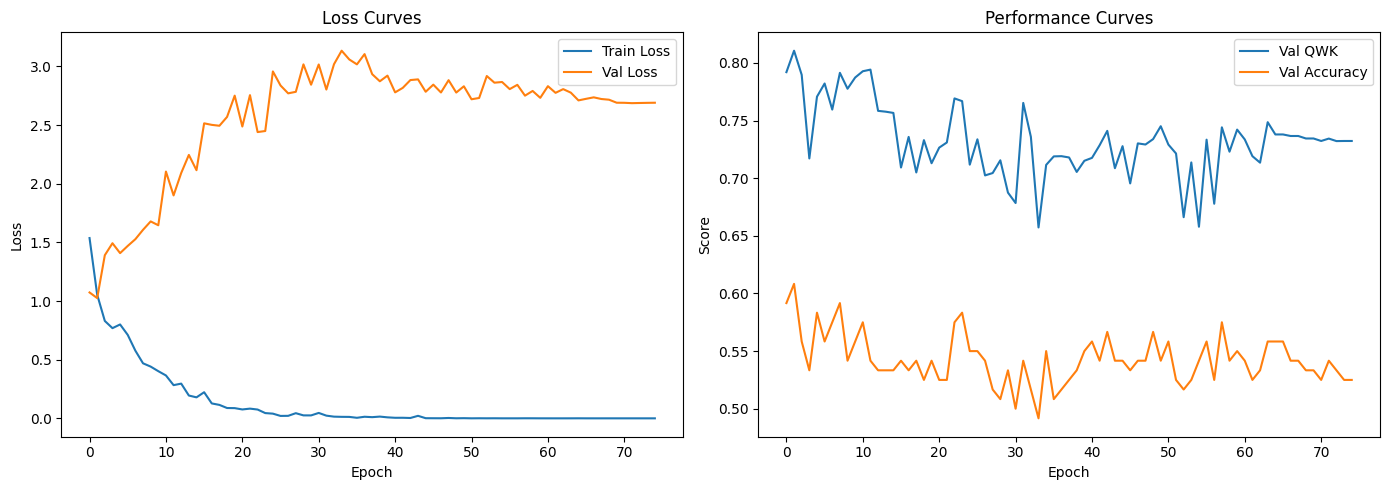


Visualizations saved to: /content/drive/MyDrive/CLAM_TR_Results/v3_improved/visualizations


In [19]:
# ============================================================================
# VISUALIZE RESULTS
# ============================================================================

if results is not None:
    # Wrap results in dict for visualization functions
    all_results = {'exp4_uni_clam_tr_improved': results}

    print('\nGenerating visualizations...')

    # Plot confusion matrix
    plot_confusion_matrix(all_results, 'exp4_uni_clam_tr_improved')

    # Plot training curves
    plot_training_curves(all_results, 'exp4_uni_clam_tr_improved')

    print(f'\nVisualizations saved to: {os.path.join(CONFIG["results_dir"], "visualizations")}')

In [20]:
# ============================================================================
# FINAL SUMMARY
# ============================================================================

if results is not None:
    print('\n' + '='*80)
    print('CLAM-TR v3 IMPROVED - FINAL RESULTS')
    print('='*80)
    print(f'\nPerformance Metrics:')
    print(f'  Quadratic Weighted Kappa: {results["qwk"]:.4f}')
    print(f'  Accuracy:                 {results["accuracy"]*100:.2f}%')
    print(f'  Macro F1-Score:           {results["macro_f1"]:.4f}')
    print(f'  AUC-ROC:                  {results["auc"]:.4f}')

    print(f'\nPer-Class F1 Scores:')
    for i, f1 in enumerate(results['per_class_f1']):
        print(f'  Grade {i}: {f1:.4f}')

    print(f'\nFiles saved:')
    print(f'  Model: {CONFIG["results_dir"]}/models/exp4_uni_clam_tr_improved_best.pt')
    print(f'  Checkpoints: {CONFIG["checkpoints_dir"]}')
    print(f'  Visualizations: {CONFIG["results_dir"]}/visualizations/')

    # Compare with baseline (if known)
    baseline_qwk = 0.83
    baseline_acc = 0.63
    target_qwk = 0.90
    target_acc = 0.70

    print(f'\n' + '='*80)
    print('IMPROVEMENT ANALYSIS')
    print('='*80)
    print(f'\nQWK:')
    print(f'  Baseline:  {baseline_qwk:.4f}')
    print(f'  Target:    {target_qwk:.4f}')
    print(f'  Achieved:  {results["qwk"]:.4f}')
    print(f'  Change:    {(results["qwk"] - baseline_qwk)*100:+.2f}%')

    print(f'\nAccuracy:')
    print(f'  Baseline:  {baseline_acc*100:.1f}%')
    print(f'  Target:    {target_acc*100:.1f}%')
    print(f'  Achieved:  {results["accuracy"]*100:.1f}%')
    print(f'  Change:    {(results["accuracy"] - baseline_acc)*100:+.1f}%')

    if results['qwk'] >= target_qwk and results['accuracy'] >= target_acc:
        print(f'\nTARGET ACHIEVED!')
    elif results['qwk'] >= baseline_qwk and results['accuracy'] >= baseline_acc:
        print(f'\nIMPROVEMENT OVER BASELINE!')
    else:
        print(f'\nNEEDS FURTHER OPTIMIZATION')

    print('='*80)


CLAM-TR v3 IMPROVED - FINAL RESULTS

Performance Metrics:
  Quadratic Weighted Kappa: 0.8106
  Accuracy:                 60.83%
  Macro F1-Score:           0.6103
  AUC-ROC:                  0.8801

Per-Class F1 Scores:
  Grade 0: 0.8000
  Grade 1: 0.4375
  Grade 2: 0.5091
  Grade 3: 0.6486
  Grade 4: 0.6000
  Grade 5: 0.6667

Files saved:
  Model: /content/drive/MyDrive/CLAM_TR_Results/v3_improved//models/exp4_uni_clam_tr_improved_best.pt
  Checkpoints: /content/drive/MyDrive/CLAM_TR_Checkpoints/v3_improved/
  Visualizations: /content/drive/MyDrive/CLAM_TR_Results/v3_improved//visualizations/

IMPROVEMENT ANALYSIS

QWK:
  Baseline:  0.8300
  Target:    0.9000
  Achieved:  0.8106
  Change:    -1.94%

Accuracy:
  Baseline:  63.0%
  Target:    70.0%
  Achieved:  60.8%
  Change:    -2.2%

NEEDS FURTHER OPTIMIZATION
